## **Week 4 Capstone - Predicting Internship Selection Outcomes**

## **Step 1: Set Up**

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree 
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
#load the week1 applicants data
df = pd.read_csv(
    r"C:\Users\Administrator\Downloads\applicants_cleaned.csv",
    parse_dates=["Application_date"]
)

## **Step 2: Extend the Dataset With New Features**

| New Feature                   | Type   | Example values                                     |
|-------------------------------|--------|----------------------------------------------------|
| num_skills_liste              | Number | How many relevant skills the applicant listed(e.g., 1-8)       |
| has_portfolio                 | Yes/No | Whether they provided a GitHub/portfolio link      |
| prior_hackathon_participation | Yes/No | Whether they'd previously joined a hackathon       |
| statement_quality_score       | Number | A simulated score(e.g. e.g 1-10) representingbhow strong their short statement was|

In [55]:
#Simulating realistically
import numpy as np
np.random.seed(42)#ensures the random data is reproducible everytime you rerun the notebook
df['num_skills_listed'] = np.random.randint(1, 9, size = len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size = len(df), p = [0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size = len(df), p = [0.3, 0.7])
df['statement_quality_scores'] = np.random.randint(1, 11, size = len(df))

To improve the analysis and prepare the dataset for machine learning, I created additional columns representing applicant characteristics that could influence internship selection.

I used NumPy to generate sample data for these new features. I also set a random seed (np.random.seed(42)) to ensure that the generated values remain consistent whenever the notebook is executed.

The following features were created:

- **num_skills_listed:** Represents the number of skills listed by each applicant. Random values between 1 and 8 were generated to simulate the number of skills provided.

- **has_portfolio:** Indicates whether an applicant has a portfolio. Applicants were randomly assigned either 'Yes' or 'No', with probabilities of 40% and 60%, respectively.

- **prior_hackathon_participation:** Indicates whether an applicant had previously participated in a hackathon. The simulated data assigned a 30% probability of 'Yes' and a 70% probability of 'No'.

- **statement_quality_scores:** Represents the quality of applicants' personal statements. This feature was intended to capture differences in the quality of application statements.

These additional columns were introduced to expand the dataset and provide more features for exploring applicant characteristics and predicting internship selection outcomes.

## **Step 3: Feature Preparation - Getting Data Ready for a Model**

#### **3.1 -- Convert Yes/No columns to 0/1**

In [56]:
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

#### **3.2 --Convert the target column to 0/1**

In [57]:
#The model needs to predict Selected vs Not Selected.Simplify the Status Column
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)
df_model = df[df['Status'] != 'Under Review'].copy()



#### **3.3-- One-hot encode the Domain column**

In [58]:
df_model = pd.get_dummies(df_model, columns = ['Domain_Applied'], drop_first =True)

In [61]:
df_model.head(5)

,Applicant_Name,Email,Phone,University_Name,Application_date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_scores,target,Domain_Applied_Computer Science,Domain_Applied_Data Science,Domain_Applied_Pure Mathematics,Domain_Applied_Web Development
2,Breanna Solis,christopher86@example.net,0018124354182x708,Egerton University,2026-05-13,Selected,5,0,0,3,1,False,False,False,True
4,Derrick Moore,kolson@example.net,5909238996,Maseno University,2026-05-12,Selected,3,0,1,5,1,True,False,False,False
6,Lucas Odonnell,fishermichael@example.org,3786250726,Moi University,2026-05-13,Rejected,5,0,0,1,0,False,False,False,True
8,Mary Lee,amyharvey@example.org,9133507350,JKUAT University,2026-05-12,Selected,7,1,1,3,1,False,False,False,True
9,Jamie Andrews,myersjohn@example.net,990.608.2287x5855,Not provided,2026-05-13,Selected,2,1,0,1,1,False,False,False,True


#### **3.4 --Select the final feature set**

In [62]:
feature_columns = ['num_skills_listed', 'has_portfolio', 
                   'prior_hackathon_participation', 'statement_quality_scores'] + [col for col in df_model.columns if col.startswith('Domain_Applied_')]
x = df_model[feature_columns]
y = df_model['target']

In [63]:
print(df_model.columns.tolist())

['Applicant_Name', 'Email', 'Phone', 'University_Name', 'Application_date', 'Status', 'num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_scores', 'target', 'Domain_Applied_Computer Science', 'Domain_Applied_Data Science', 'Domain_Applied_Pure Mathematics', 'Domain_Applied_Web Development']


## **Step 4: Train/ Test Split**

In [64]:
x_train, x_test, y_train, y_test = train_test_split(
x, y, test_size = 0.2, random_state = 42
)

I divided the dataset into training and testing sets using Scikit-learn's train_test_split() function.

The dataset was split into two portions:

- **Training data (80%):** Used to train the Logistic Regression model so that it could learn patterns from the applicant information.

- **Testing data (20%):** Used to evaluate how well the trained model predicts internship selection outcomes using data it has not seen during training.

I also used random_state=42 to ensure that the data is split consistently whenever the notebook is executed.

This approach helps assess the model's ability to make predictions on unseen applicant data.

## **Step 5: Train the Model**

In [65]:
#Logistic model
model = LogisticRegression(max_iter = 1000)
model.fit(x_train, y_train)

#Make predictions on the test set
y_pred = model.predict(x_test)
display(y_pred)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [66]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(results)

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,0,1
8,1,1
9,1,1


## **Step 6: Evaluate the Model - Honestly**

#### **6.1 Accuracy**

In [67]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 84.62%


The Logistic Regression model achieved an accuracy of 84.62% on the test dataset.

This means that the model correctly predicted the selection outcomes of approximately 85% of the applicants in the test dataset. In other words, it made correct predictions for most applicants, demonstrating promising classification performance.

However, since the test dataset contains only 13 applicants, the accuracy should be interpreted cautiously. Testing the model on a larger dataset would provide a more reliable assessment of its ability to predict internship selection outcomes.

#### **6.2 -- Precision, Recall, and/or Confusion Matrix**

Precision:  91.67%
Recall:  91.67%


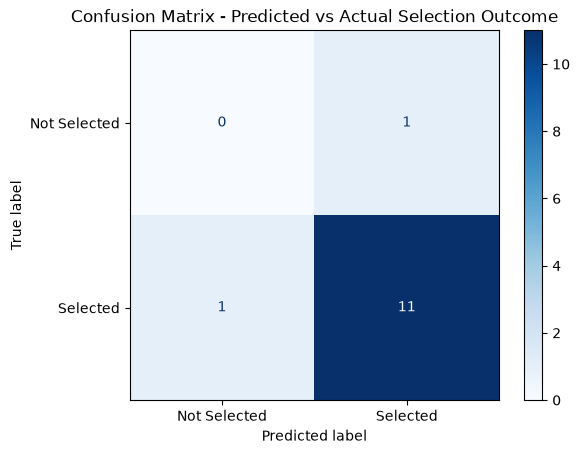

In [68]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print(f"Precision: {precision: .2%}")
print(f"Recall: {precision: .2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = ['Not Selected', 'Selected'])
disp.plot(cmap = 'Blues')
plt.title('Confusion Matrix - Predicted vs Actual Selection Outcome')
plt.show()

                                                                       

- **Precision:** "Of all the applicants my model predicted would be Selected, what percentage were actually Selected? High precision means fewer false promises."The results show that approximately [92]% applicants predicted as selected were genuinely selected.

- **Recall:** "Of all the applicants who were actually Selected, what percentage did my model correctly catch?" High recall means fewer missed strong candidates." The result means that the model successfully identified approximately [92]% of applicants who were actually selected.

- **Confusion matrix:** "A simple 2x2 grid showing exactly how many predictions fell into each of the 4 buckets: Correctly predicted Selected(false positive), correctly predicted Not Selected(false negative)."The model correctly identified 11 out of 13 actually-selected applicants, but incorrectly flagged 1 non-selected applicant as likely selected."

#### **6.3 --The Model's Limitations**

- The dataset is **small and partly** simulated(4 of the features were artificially generated, not real historical behavour).
- With a small test set, results can shift noticeably if you resplit the data differently - these numbers are illustrative of the method, not a production-ready guarantee.
- The model could reflect or amplify **bias** already present in past selection decision(e.g if certain universities were historically favored for reasons unrelated to merit, the model would learn and repeat that pattern) = this is a genuine, important concern with any predictive hiring/selection tool, and should never be glossed over.
- This method should not be treated as a **decision support tool**, a replacement for human review. 


## **Step 7: Which features mattered most?**

In [69]:
#Under Logistic Regression
coefficients = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by = 'Coefficient', ascending = False)

print(coefficients)


                           Feature  Coefficient
7   Domain_Applied_Web Development     0.594522
6  Domain_Applied_Pure Mathematics     0.218999
5      Domain_Applied_Data Science     0.197986
2    prior_hackathon_participation     0.093578
4  Domain_Applied_Computer Science     0.046529
3         statement_quality_scores    -0.061704
0                num_skills_listed    -0.137786
1                    has_portfolio    -0.649038


A positive coefficient means that feature increases the likelihood of being predicted 'Selected' as it goes up; a negative coefficient means the opposite.The feature with the largest positive coefficient is the strongest predictor in the model.

*The model suggests that the application domain, particularly Web Development, had a positive relationship with internship selection. Previous hackathon participation also had a positive relationship.*

*Interestingly, having a portfolio, listing more skills, and statement quality scores showed negative relationships with selection in this dataset.*

## **Step 8: Write the Excutive Summary**

## **Excutive Summary**
**What we did:** We buit a simple prediction model using past applicant data to explore which factors are associated with being selected for the NextGenLearners internship program.

**What we found:** The model correctly predicted selection outcomes for about [92]% of applicants in our test group.The model suggests that applicants who applied for Web Development, Pure Mathematics, and Data Science had a higher likelihood of being selected. Applicants who applied for Computer Science also showed a slight positive relationship with selection. Additionally, applicants who had participated in previous hackathons were slightly more likely to be selected than those who had not participated.

**Important coveats:** This analysis used a small, partly simulated dataset - several factors (like skill count and statement quality) were artificially generated for this exercise rather than pulled from real historical records.Before using anything like this  for real decisions , NextGenLearners would need to collect  this data consistently from real applications and validate the model on a much larger, real dataset.The model should be treated as decision-support tool to assist reviewers, never as automatic replacement for human judgement - especially given the risk that it could unintentionally repeat biases from past decisions.

**Recommendation:** Consider adding a question about previous hackathon participation to the application form. This will help the organisation establish whether applicants have participated in hackathons before, since this information may help identify applicants who are more likely to succeed in the selection process.